In [56]:
from photutils.segmentation import (SourceCatalog, deblend_sources, detect_sources, detect_threshold)
from astropy.io import fits
from photutils.aperture import CircularAperture
from astropy.stats import mad_std
import numpy as np
from astropy.visualization import ZScaleInterval
import matplotlib.pyplot as plt
from astropy.modeling import models, fitting
from astropy.wcs import WCS

from photutils.profiles import RadialProfile

from matplotlib.patches import Circle

In [2]:
#Abrimos el fits de las estrellas
star_1b = fits.open('Star1_B.fits')[0].data
star_1v = fits.open('Star1_V.fits')[0].data
star_2b = fits.open('Star2_B.fits')[0].data
star_2v = fits.open('Star2_V.fits')[0].data

In [3]:
fits.open('Star1_B.fits')[0].header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 4096                                                  
NAXIS2  =                 4096                                                  
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
OBSERVER= 'Cortes, Martinez, Soto' / SBIGFITSEXT The name of the observer       
ORIGIN  = 'MAS500  '           / Description of location                        
TELESCOP= 'MAS500  '           / SBIGFITSEXT The model Telescope                
FOCALLEN=                6500. / SBIGFITSEXT Telescope focal length in mm       
APTDIA  =                 500. / SBIGFITSEXT Aperture diameter in mm            
SBUUID  = '{860cfa7f-7142-46

In [4]:
#Calcular desviación del fondo (background noise)
bkg_1b = mad_std(star_1b)
bkg_1v = mad_std(star_1v)
bkg_2b = mad_std(star_2b)
bkg_2v = mad_std(star_2v)

In [5]:
#Threshold, para cada estrella
threshold_1b = detect_threshold(star_1b, nsigma = 5)
threshold_1v = detect_threshold(star_1v, nsigma = 5)
threshold_2b = detect_threshold(star_2b, nsigma = 5)
threshold_2v = detect_threshold(star_2v, nsigma = 5)
#Detectamos fuentes
sour_1b = detect_sources(star_1b, threshold_1b, npixels=5)
sour_1v = detect_sources(star_1v, threshold_1v, npixels=5)
sour_2b = detect_sources(star_2b, threshold_2b, npixels=5)
sour_2v = detect_sources(star_2v, threshold_2v, npixels=5)

In [6]:
#Crear catálogos de las fuentes detectadas
cat_1b = SourceCatalog(star_1b, sour_1b)
cat_1v = SourceCatalog(star_1v, sour_1v)
cat_2b = SourceCatalog(star_2b, sour_2b)
cat_2v = SourceCatalog(star_2v, sour_2v)

In [7]:
#Lo pasamos a tabla
tabla_1b = cat_1b.to_table()
tabla_1v = cat_1v.to_table()
tabla_2b = cat_2b.to_table()
tabla_2v = cat_2v.to_table()

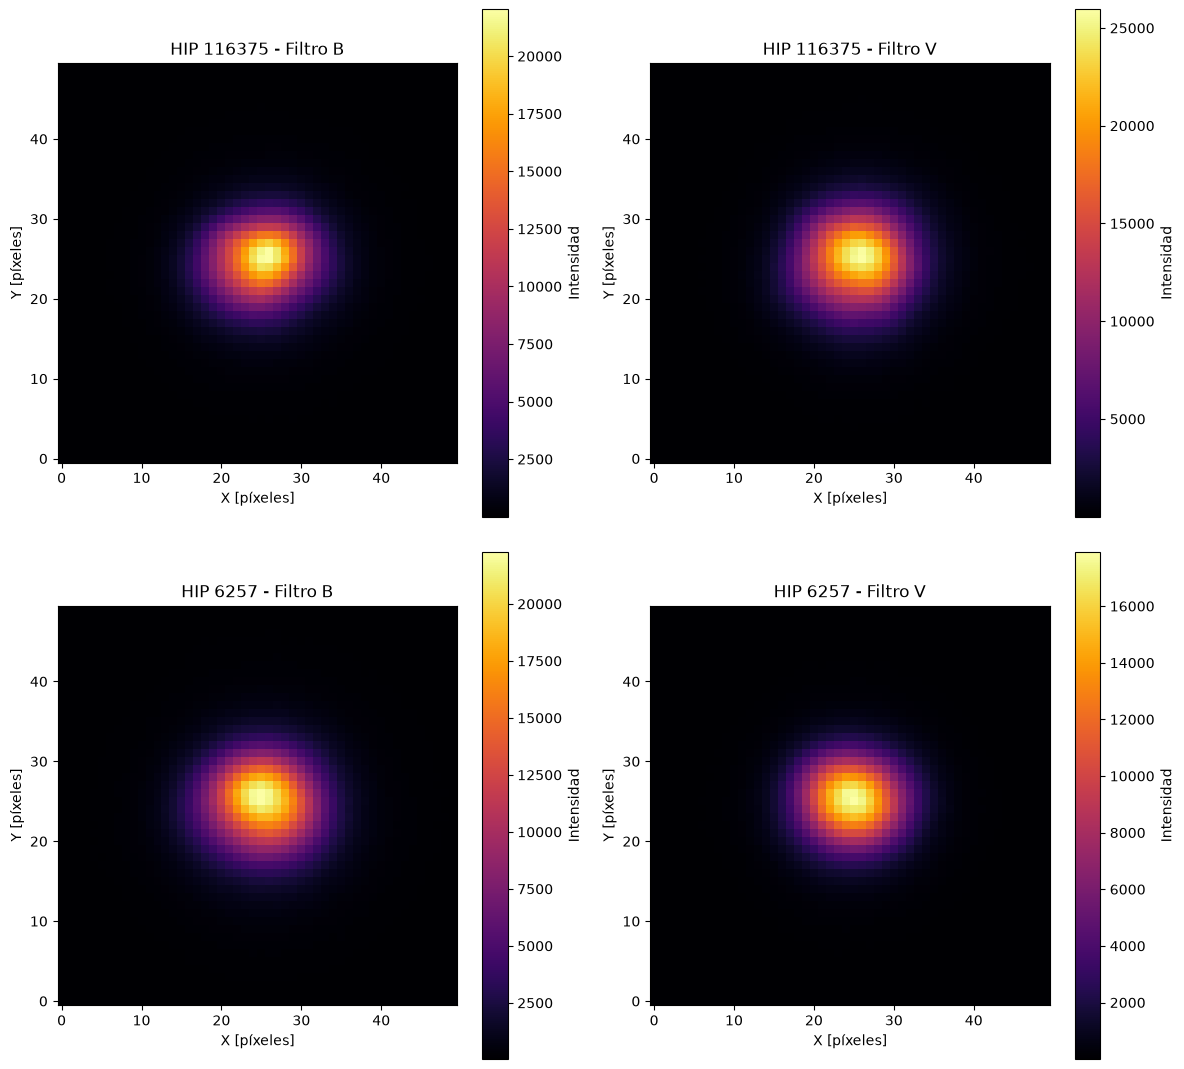

In [8]:
# Tablas e imágenes
tablas = [tabla_2b, tabla_2v, tabla_1b, tabla_1v]
imagenes = [star_2b, star_2v, star_1b, star_1v]

titulos = [
    'HIP 116375 - Filtro B',
    'HIP 116375 - Filtro V',
    'HIP 6257 - Filtro B',
    'HIP 6257 - Filtro V'
]

fig, ax = plt.subplots(2, 2, figsize=(12, 11))

for i in range(4):

    # Coordenadas de la estrella de mayor área
    indice = np.argmax(tablas[i]['area'])

    x = int(round(tablas[i]['xcentroid'][indice]))
    y = int(round(tablas[i]['ycentroid'][indice]))

    # Recorte de 50 x 50 píxeles
    recorte = imagenes[i][y-25:y+25, x-25:x+25]

    # Visualización
    im = ax.flat[i].imshow(recorte, origin='lower', cmap='inferno')
    ax.flat[i].set_title(titulos[i])
    ax.flat[i].set_xlabel('X [píxeles]')
    ax.flat[i].set_ylabel('Y [píxeles]')

    plt.colorbar(im, ax=ax.flat[i], label='Intensidad')

plt.tight_layout()
plt.show()

In [80]:
header_1b = fits.open('Star1_B.fits')[0].header
header_1v = fits.open('Star1_V.fits')[0].header
header_2b = fits.open('Star2_B.fits')[0].header
header_2v = fits.open('Star2_V.fits')[0].header

Set OBSGEO-Y to -5196255.928 from OBSGEO-[LBH].
Set OBSGEO-Z to -3215219.022 from OBSGEO-[LBH]'. [astropy.wcs.wcs]
Set OBSGEO-Y to -5196255.928 from OBSGEO-[LBH].
Set OBSGEO-Z to -3215219.022 from OBSGEO-[LBH]'. [astropy.wcs.wcs]
Set OBSGEO-Y to -5196255.928 from OBSGEO-[LBH].
Set OBSGEO-Z to -3215219.022 from OBSGEO-[LBH]'. [astropy.wcs.wcs]
Set OBSGEO-Y to -5196255.928 from OBSGEO-[LBH].
Set OBSGEO-Z to -3215219.022 from OBSGEO-[LBH]'. [astropy.wcs.wcs]


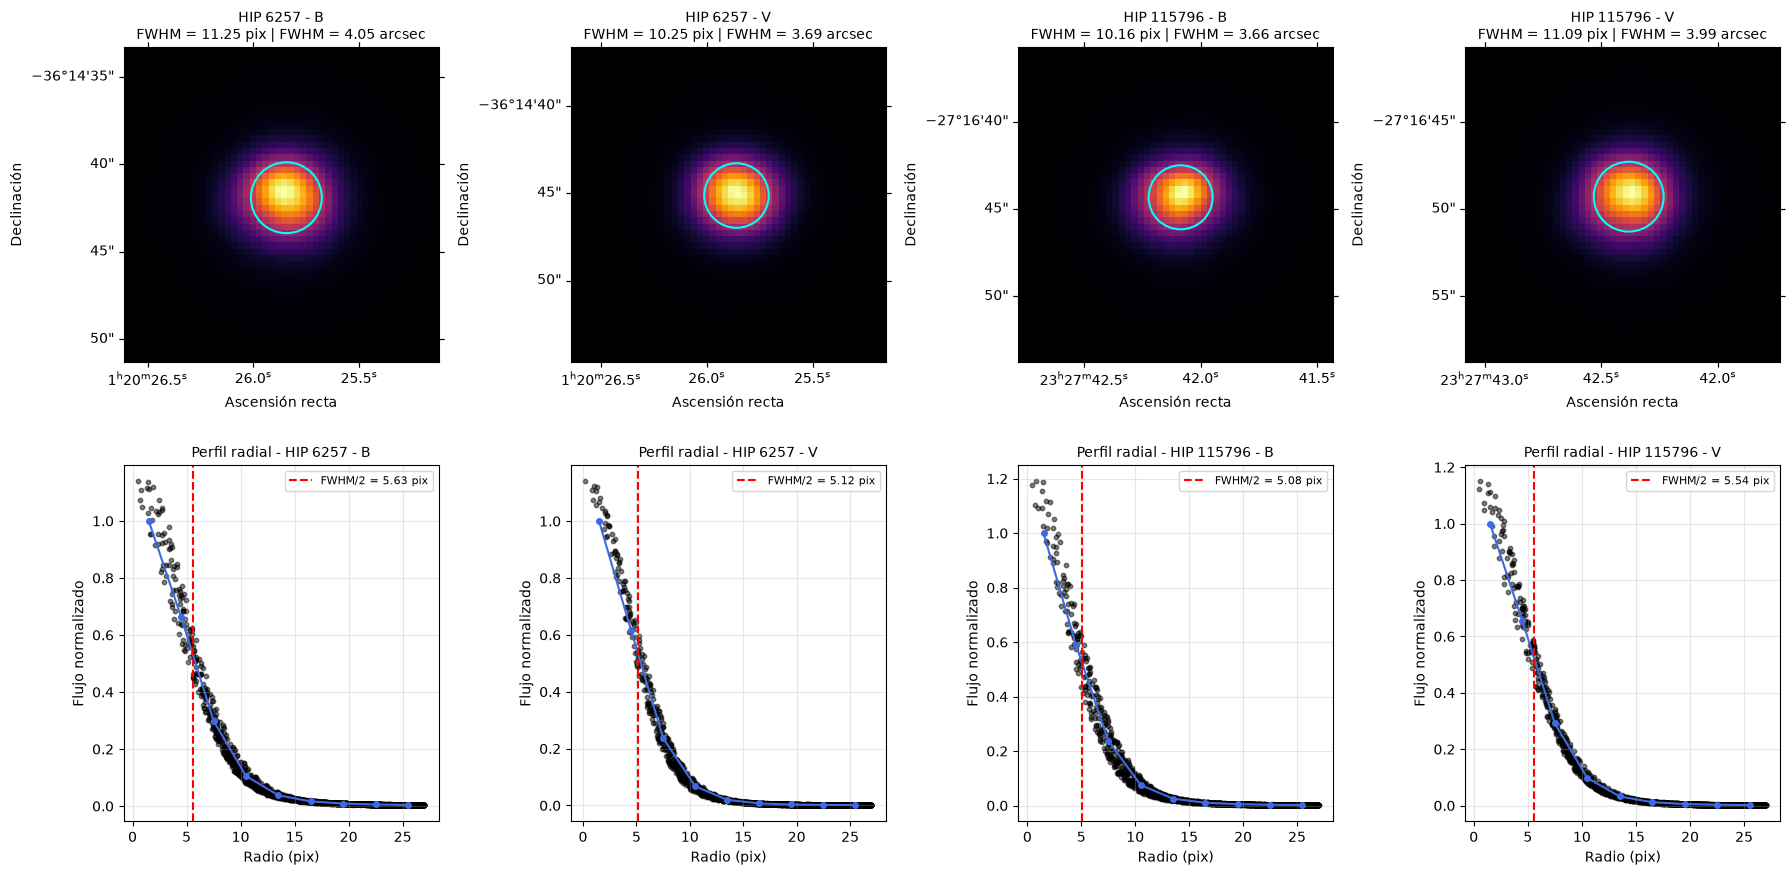

In [84]:
data = [star_1b, star_1v, star_2b, star_2v]

tables = [tabla_1b, tabla_1v, tabla_2b, tabla_2v]

headers = [header_1b, header_1v, header_2b, header_2v]

nombres = ['HIP 6257 - B', 'HIP 6257 - V',
           'HIP 115796 - B', 'HIP 115796 - V']

r = np.arange(0, 30, 3)

pixscale = 0.36 

fwhm_pix = np.zeros(len(data))
fwhm_arcsec = np.zeros(len(data))

# Figura general
fig = plt.figure(figsize=(18, 9))

for i in range(len(data)):

    data_i = np.nan_to_num(data[i], nan=0, posinf=0, neginf=0)
    table_i = tables[i]

    star_index = np.argmax(table_i['area'])

    x_centroid_star = table_i['xcentroid'][star_index]
    y_centroid_star = table_i['ycentroid'][star_index]

    xy_centroid = [x_centroid_star, y_centroid_star]

    rp = RadialProfile(data_i, xy_centroid, r)
    rp.normalize()

    fwhm = rp.gaussian_fwhm

    fwhm_pix[i] = fwhm
    fwhm_arcsec[i] = fwhm * pixscale

    profile = rp.profile
    radius = rp.radius
    data_profile = rp.data_profile
    data_radius = rp.data_radius

    x0 = max(0, int(x_centroid_star) - 25)
    x1 = min(data_i.shape[1], int(x_centroid_star) + 25)

    y0 = max(0, int(y_centroid_star) - 25)
    y1 = min(data_i.shape[0], int(y_centroid_star) + 25)

    star = data_i[y0:y1, x0:x1]

    wcs_i = WCS(headers[i]).slice(
        (slice(y0, y1), slice(x0, x1))
    )
    
    ax1 = fig.add_subplot(2, 4, i + 1, projection=wcs_i)

    im = ax1.imshow(
        star,
        origin='lower',
        cmap='inferno',
        interpolation='nearest'
    )

    x_local = x_centroid_star - x0
    y_local = y_centroid_star - y0

    circle = Circle(
        (x_local, y_local),
        fwhm / 2,
        edgecolor='cyan',
        facecolor='none',
        linewidth=1.5
    )

    ax1.add_patch(circle)

    ax1.set_title(
        f'{nombres[i]}\nFWHM = {fwhm:.2f} pix | FWHM = {fwhm_arcsec[i]:.2f} arcsec',
        fontsize=10
    )

    ax1.set_xlabel('Ascensión recta')
    ax1.set_ylabel('Declinación')

    ax2 = fig.add_subplot(2, 4, i + 5)

    ax2.plot(radius, profile, 'o-', color='royalblue',
             markersize=4)

    ax2.scatter(
        data_radius,
        data_profile,
        s=10,
        color='black',
        alpha=0.5
    )

    ax2.axvline(
        fwhm / 2,
        color='red',
        linestyle='--',
        label=f'FWHM/2 = {fwhm/2:.2f} pix'
    )

    ax2.set_title(f'Perfil radial - {nombres[i]}', fontsize=10)
    ax2.set_xlabel('Radio (pix)')
    ax2.set_ylabel('Flujo normalizado')
    ax2.legend(fontsize=8)
    ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()